# Lab 03: Edge Detection Techniques and Their Impact on Classification Performance

**Pipeline:** Sobel / Prewitt / Laplacian / LoG / Canny → noise & smoothing study (Table 1) → Canny parameter study (Table 2) → classification on **Raw (Set A)**, **Filtered (Set B)** and **Edge (Set C)** images with SVM, Random Forest, KNN and two CNNs (Table 3) → confusion matrices + bar chart.

> **Use your Lab 01/02 dataset:** in the config cell set `data_mode='folder'` and `data_dir` to a folder with one sub-folder per class (and set `best_filter` to your Lab 02 winner). The default `cifar10` mode just gives a runnable out-of-the-box demo on 4 classes.
> Every table below is **computed by the code** (nothing is typed in by hand). Run with *Runtime → Run all*.

## 0. Setup & configuration

In [ ]:
!pip -q install opencv-python-headless

In [ ]:
import os, time, random, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace
from skimage.filters import threshold_otsu
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import torch, torch.nn as nn
warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)

CFG = dict(
    data_mode="cifar10",             # 'cifar10' (demo) | 'folder' (YOUR Lab 01/02 data) | 'digits' (offline test)
    data_dir="/content/dataset",     # used when data_mode == 'folder'  (data_dir/<class_name>/*.jpg|png)
    classes=["airplane", "automobile", "cat", "ship"],   # cifar10 classes (use >= 3). For 'folder', None = all sub-folders
    n_per_class=500, img=64, seed=42,
    best_filter="gaussian",          # Set B filter = your Lab 02 winner: 'gaussian' | 'median' | 'bilateral'
    epochs=15, batch=64, lr=1e-3,    # identical for every CNN run
    n_sample_per_class=6,            # images/class used in the noise + Canny studies
    noise_sigma=25, sp_amount=0.05,
)
SEED = CFG["seed"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


## 1. Dataset (grayscale, fixed train/val/test split shared by every experiment)

In [ ]:
S = CFG["img"]
def load_dataset():
    imgs, labels = [], []
    if CFG["data_mode"] == "cifar10":
        import torchvision
        ds = torchvision.datasets.CIFAR10("data", train=True, download=True)
        y = np.array(ds.targets); names = CFG["classes"]
        for k, c in enumerate(names):
            for i in np.flatnonzero(y == ds.classes.index(c))[:CFG["n_per_class"]]:
                g = cv2.cvtColor(ds.data[i], cv2.COLOR_RGB2GRAY)
                imgs.append(cv2.resize(g, (S, S), interpolation=cv2.INTER_CUBIC)); labels.append(k)
    elif CFG["data_mode"] == "folder":
        root = CFG["data_dir"]
        names = CFG["classes"] or sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
        for k, c in enumerate(names):
            files = sorted(f for f in os.listdir(os.path.join(root, c)) if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif")))
            for f in files[:CFG["n_per_class"]]:
                g = cv2.imread(os.path.join(root, c, f), cv2.IMREAD_GRAYSCALE)
                if g is None: continue
                imgs.append(cv2.resize(g, (S, S), interpolation=cv2.INTER_AREA)); labels.append(k)
    elif CFG["data_mode"] == "digits":
        from sklearn.datasets import load_digits
        d = load_digits(n_class=4); names = [str(i) for i in range(4)]
        for im, l in zip(d.images, d.target):
            imgs.append(cv2.resize((im * 16).astype(np.uint8), (S, S), interpolation=cv2.INTER_CUBIC)); labels.append(int(l))
    return np.array(imgs, np.uint8), np.array(labels), list(names)

imgs, y, class_names = load_dataset()
n_classes = len(class_names)
idx = np.arange(len(y))
tr, tmp = train_test_split(idx, test_size=0.4, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.5, stratify=y[tmp], random_state=SEED)
print("Classes:", class_names, "| images:", imgs.shape, "| train/val/test:", len(tr), len(va), len(te))

# representative samples: first n images of every class from the TRAIN split
samp = np.concatenate([tr[y[tr] == c][:CFG["n_sample_per_class"]] for c in range(n_classes)])
rep = [tr[y[tr] == c][0] for c in range(n_classes)]   # one representative per class

100%|██████████| 170M/170M [33:27<00:00, 84.9kB/s]


Classes: ['airplane', 'automobile', 'cat', 'ship'] | images: (2000, 64, 64) | train/val/test: 1200 400 400


## 2. Edge detectors and noise / filtering helpers

In [ ]:
KP_X = np.array([[-1, 0, 1]] * 3, np.float32); KP_Y = KP_X.T.copy()

def sobel_xy(img):
    f = img.astype(np.float32)
    gx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3); gy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3)
    return gx, gy, np.hypot(gx, gy)
def prewitt(img):
    f = img.astype(np.float32)
    return np.hypot(cv2.filter2D(f, cv2.CV_32F, KP_X), cv2.filter2D(f, cv2.CV_32F, KP_Y))
def laplacian(img):  return np.abs(cv2.Laplacian(img.astype(np.float32), cv2.CV_32F, ksize=3))
def log_edge(img, sigma=1.5): return np.abs(gaussian_laplace(img.astype(np.float32), sigma))
def canny(img, lo=50, hi=150, k=5):
    return cv2.Canny(cv2.GaussianBlur(img, (k, k), 0), lo, hi)       # 0 / 255

DETECTORS = {"Sobel": lambda x: sobel_xy(x)[2], "Prewitt": prewitt, "Laplacian": laplacian,
             "LoG": log_edge, "Canny": lambda x: canny(x, 50, 150, 5)}

def add_gaussian(img, rng, sigma=None):
    return np.clip(img.astype(np.float32) + rng.normal(0, sigma or CFG["noise_sigma"], img.shape), 0, 255).astype(np.uint8)
def add_salt_pepper(img, rng, amount=None):
    out = img.copy(); r = rng.random(img.shape); a = amount or CFG["sp_amount"]
    out[r < a / 2] = 0; out[r > 1 - a / 2] = 255; return out

FILTERS = {"gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median":   lambda x: cv2.medianBlur(x, 3),
           "bilateral": lambda x: cv2.bilateralFilter(x, 7, 50, 50)}

def to_u8(m):                                 # per-image min-max -> uint8 edge image
    if m.dtype == np.uint8: return m
    return (255 * m / (m.max() + 1e-6)).astype(np.uint8)

## Task 1 — Comparative edge detection

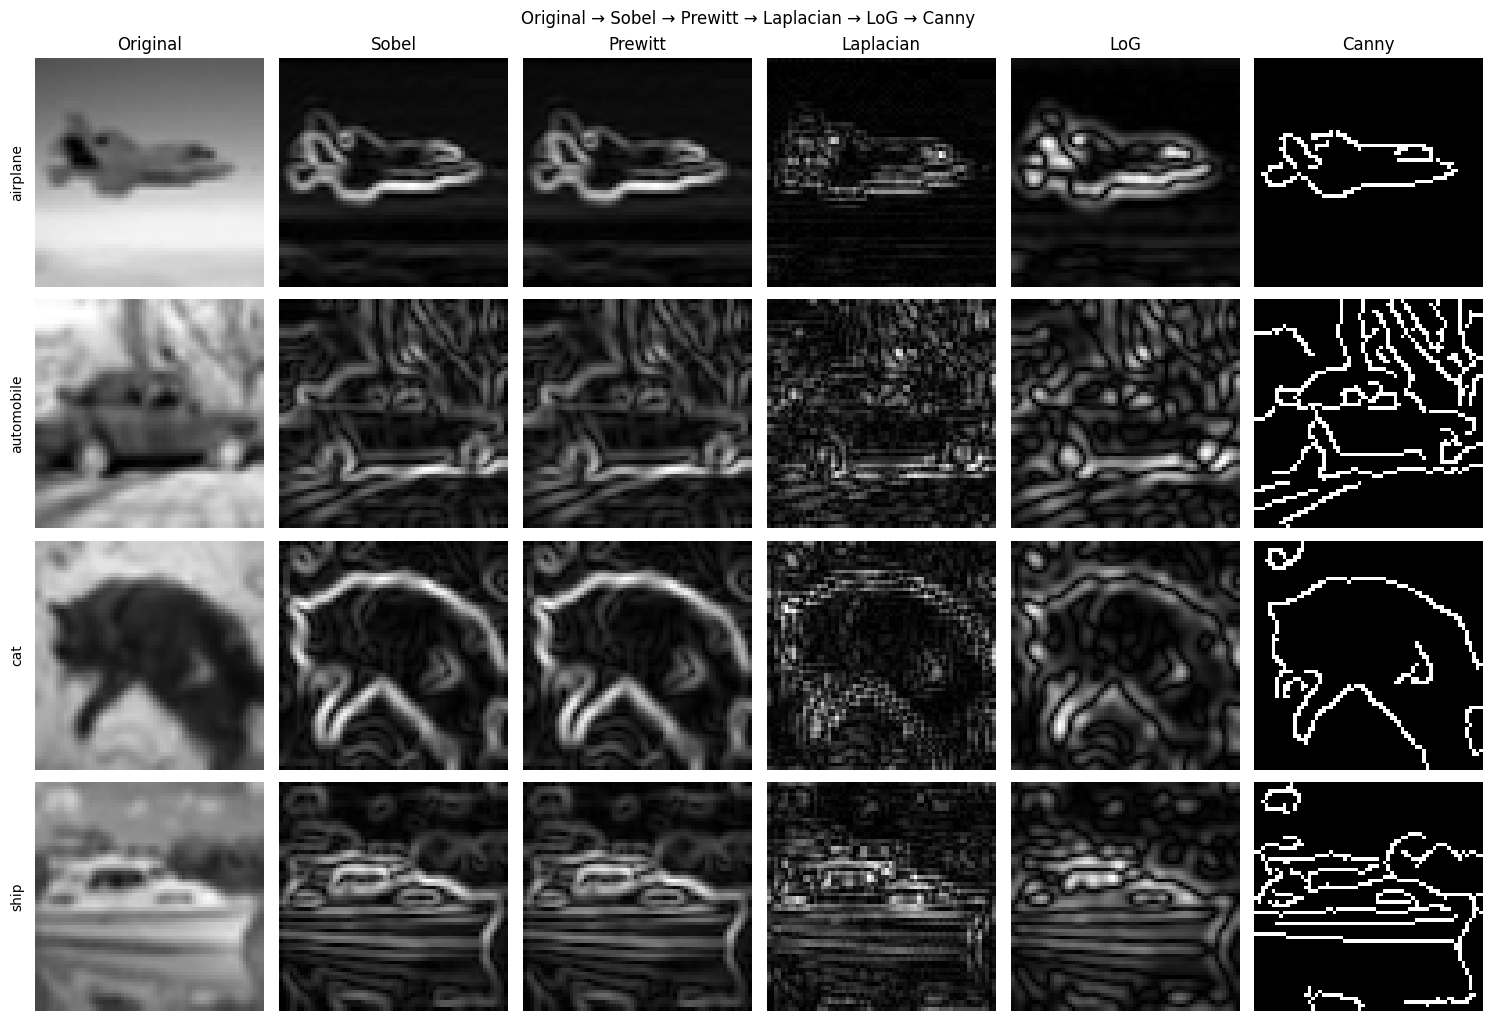

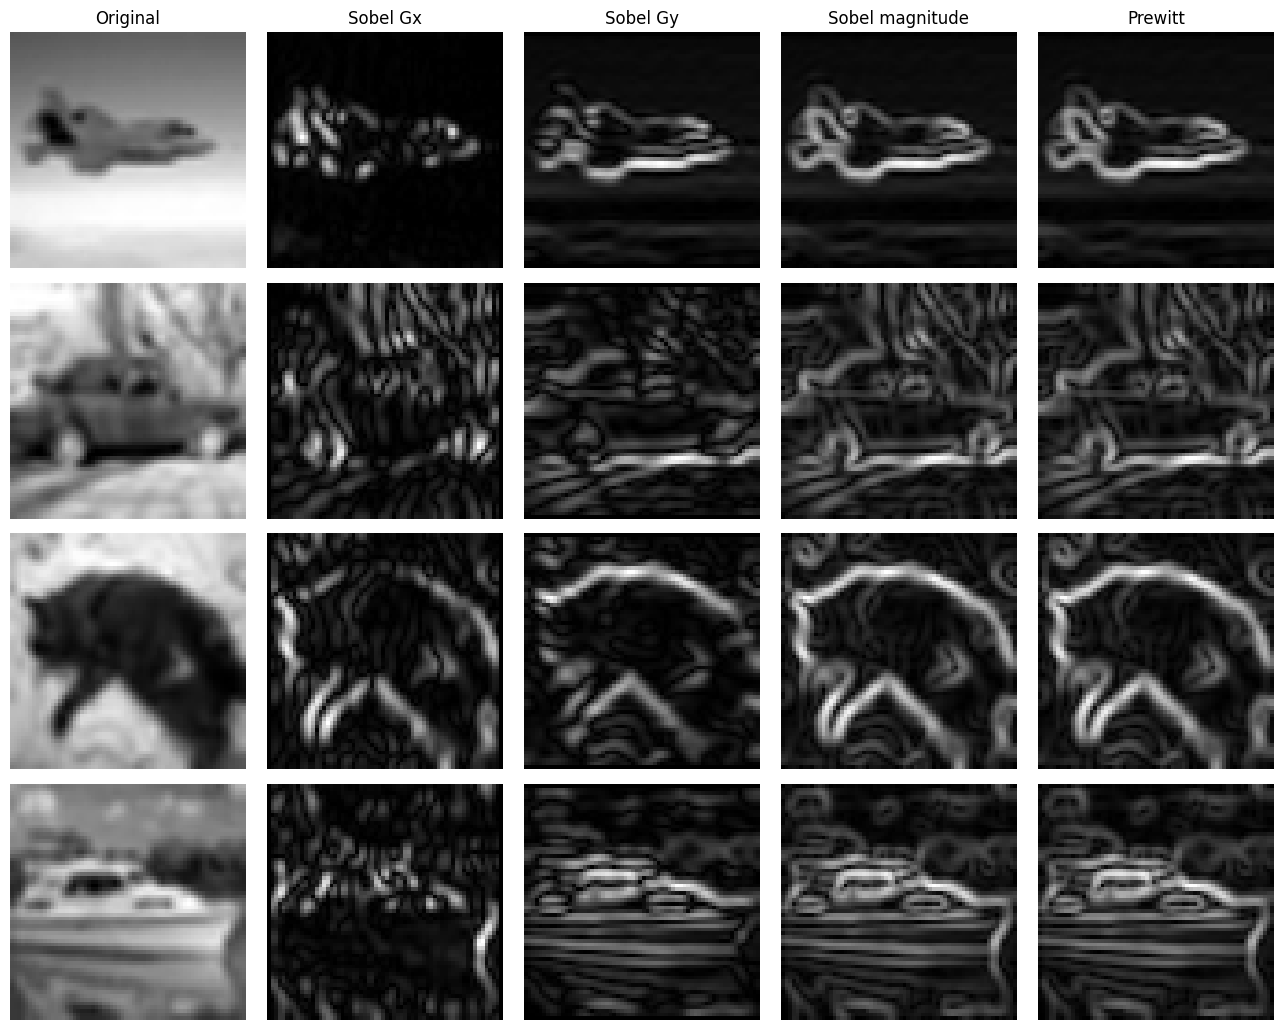

In [ ]:
fig, ax = plt.subplots(n_classes, 6, figsize=(15, 2.6 * n_classes))
cols = ["Original", "Sobel", "Prewitt", "Laplacian", "LoG", "Canny"]
for r, i in enumerate(rep):
    im = imgs[i]
    outs = [im] + [to_u8(DETECTORS[k](im)) for k in cols[1:]]
    for c, o in enumerate(outs):
        ax[r, c].imshow(o, cmap="gray", vmin=0, vmax=255); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(cols[c])
    ax[r, 0].text(-0.05, 0.5, class_names[r], transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("Original → Sobel → Prewitt → Laplacian → LoG → Canny"); plt.tight_layout()
plt.savefig("results/task1_edge_comparison.png", dpi=150); plt.show()

# first-order detail: Gx, Gy, magnitude, Prewitt
fig, ax = plt.subplots(n_classes, 5, figsize=(13, 2.6 * n_classes))
for r, i in enumerate(rep):
    gx, gy, mg = sobel_xy(imgs[i])
    for c, (o, t) in enumerate([(imgs[i], "Original"), (np.abs(gx), "Sobel Gx"), (np.abs(gy), "Sobel Gy"), (mg, "Sobel magnitude"), (prewitt(imgs[i]), "Prewitt")]):
        ax[r, c].imshow(to_u8(o) if c else o, cmap="gray"); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(t)
plt.tight_layout(); plt.savefig("results/task1_first_order.png", dpi=150); plt.show()

## Task 2 — Effect of noise on edge detection

Conditions: original · Gaussian noise (σ=25) · salt-and-pepper (5 %) · Gaussian noise → Gaussian filter (5×5) · salt-and-pepper → median filter (3×3).

**How Table 1 is quantified.** For each detector the clean-image edge map is binarised (Otsu on the clean map; Canny is already binary). The *same* threshold is then applied to every condition. Against the clean map (1-pixel tolerance) we measure
**false edges = 1 − precision**, **broken/missed edges = 1 − recall**, **edge quality = edge F1**, **edge-density ratio** (noisy ÷ clean) and **segment-count ratio** (connected edge fragments, a proxy for continuity). Noise sensitivity = *Low* (F1 loss < 25 %), *Medium* (< 50 %), *High* (≥ 50 %). Values are means over the sample images.

In [ ]:
CONDS = ["Original", "Gaussian noise", "Salt & pepper noise",
         "Gaussian noise + Gaussian filter", "Salt & pepper noise + Median filter"]
def make_cond(img, cond, seed):
    rng = np.random.default_rng(seed)
    if cond == "Original": return img
    if cond.startswith("Gaussian"):
        n = add_gaussian(img, rng); return n if cond == "Gaussian noise" else cv2.GaussianBlur(n, (5, 5), 0)
    n = add_salt_pepper(img, rng);  return n if cond == "Salt & pepper noise" else cv2.medianBlur(n, 3)

def n_segments(b): return max(cv2.connectedComponents(b.astype(np.uint8), connectivity=8)[0] - 1, 1)
def prf(ref, pred):
    k = np.ones((3, 3), np.uint8)
    rd = cv2.dilate(ref.astype(np.uint8), k).astype(bool); pdl = cv2.dilate(pred.astype(np.uint8), k).astype(bool)
    p = (pred & rd).sum() / max(pred.sum(), 1); r = (ref & pdl).sum() / max(ref.sum(), 1)
    return p, r, (2 * p * r / (p + r) if p + r > 0 else 0.0)

rows = []
for name, det in DETECTORS.items():
    for ii in samp:
        clean = imgs[ii]; m0 = det(clean)
        if name == "Canny": s, T = 255.0, 0.5
        else:
            s = np.percentile(m0, 99) + 1e-6
            try: T = threshold_otsu(np.clip(m0 / s, 0, 1))
            except Exception: T = 0.5
        ref = (m0 / s) > T
        for cond in CONDS:
            pred = ((det(make_cond(clean, cond, SEED + int(ii))) / s) > T)
            p, r, f = prf(ref, pred)
            rows.append(dict(Detector=name, Condition=cond, precision=p, recall=r, f1=f,
                             density=100 * pred.mean(), dens_ratio=pred.sum() / max(ref.sum(), 1),
                             seg_ratio=n_segments(pred) / n_segments(ref)))
noise_df = pd.DataFrame(rows).groupby(["Detector", "Condition"], sort=False).mean().reset_index()
noise_df.to_csv("results/noise_full_matrix.csv", index=False)

def sens(f): return "Low" if 1 - f < .25 else ("Medium" if 1 - f < .5 else "High")
T1_ROWS = [("Sobel", "Original"), ("Sobel", "Gaussian noise"), ("Sobel", "Salt & pepper noise"),
           ("Sobel", "Gaussian noise + Gaussian filter"), ("Sobel", "Salt & pepper noise + Median filter"),
           ("Prewitt", "Original"), ("Laplacian", "Original"), ("LoG", "Gaussian noise + Gaussian filter"),
           ("Canny", "Original"), ("Canny", "Gaussian noise + Gaussian filter"), ("Canny", "Salt & pepper noise + Median filter")]
t1 = []
for d, c in T1_ROWS:
    r = noise_df[(noise_df.Detector == d) & (noise_df.Condition == c)].iloc[0]
    noisy = c != "Original"
    pre = "None" if c in ("Original", "Gaussian noise", "Salt & pepper noise") else ("Gaussian filter" if "Gaussian filter" in c else "Median filter")
    if d == "Canny" and c == "Original": pre = "Built-in smoothing (Gaussian 5×5)"
    t1.append({"Edge Detector": d, "Input Image": "Noisy" if noisy else "Original",
               "Noise Type": "None" if not noisy else ("Gaussian" if c.startswith("Gaussian") else "Salt & Pepper"),
               "Preprocessing": pre,
               "Edge Quality (F1 vs clean)": "Reference" if not noisy else round(r.f1, 3),
               "Noise Sensitivity": "—" if not noisy else sens(r.f1),
               "Observations": (f"edge density {r.density:.1f}% of pixels" if not noisy else
                                f"false edges {100*(1-r.precision):.0f}%, broken/missed {100*(1-r.recall):.0f}%, "
                                f"edge density ×{r.dens_ratio:.2f}, fragments ×{r.seg_ratio:.2f}")})
table1 = pd.DataFrame(t1); table1.to_csv("results/table1_noise.csv", index=False)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)
table1

,Edge Detector,Input Image,Noise Type,Preprocessing,Edge Quality (F1 vs clean),Noise Sensitivity,Observations
0,Sobel,Original,None,None,Reference,—,edge density 23.1% of pixels
1,Sobel,Noisy,Gaussian,None,0.746,Medium,"false edges 39%, broken/missed 0%, edge density ×2.17, fragments ×6.90"
2,Sobel,Noisy,Salt & Pepper,None,0.787,Low,"false edges 34%, broken/missed 0%, edge density ×1.87, fragments ×4.24"
3,Sobel,Noisy,Gaussian,Gaussian filter,0.935,Low,"false edges 2%, broken/missed 10%, edge density ×0.79, fragments ×1.87"
4,Sobel,Noisy,Salt & Pepper,Median filter,0.989,Low,"false edges 0%, broken/missed 2%, edge density ×0.86, fragments ×1.11"
5,Prewitt,Original,None,None,Reference,—,edge density 23.2% of pixels
6,Laplacian,Original,None,None,Reference,—,edge density 19.5% of pixels
7,LoG,Noisy,Gaussian,Gaussian filter,0.92,Low,"false edges 4%, broken/missed 11%, edge density ×0.77, fragments ×1.62"
8,Canny,Original,None,Built-in smoothing (Gaussian 5×5),Reference,—,edge density 11.1% of pixels
9,Canny,Noisy,Gaussian,Gaussian filter,0.873,Low,"false edges 7%, broken/missed 17%, edge density ×0.89, fragments ×1.04"


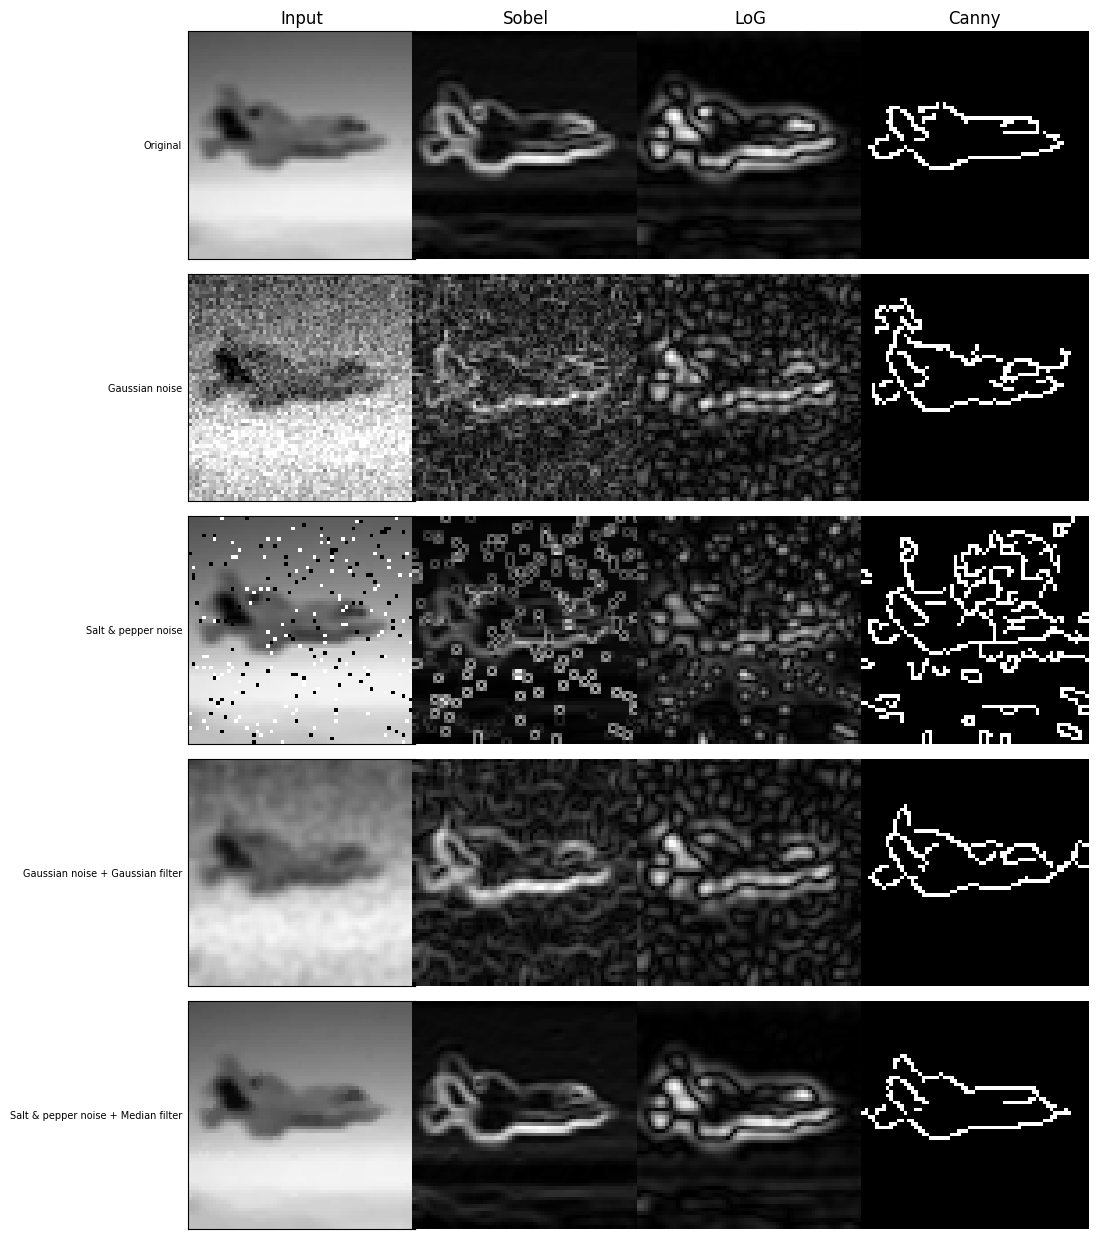

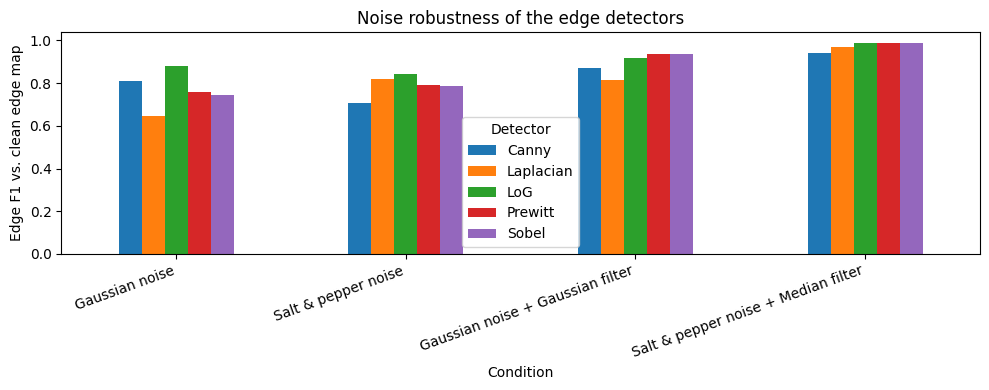

Detector,Canny,Laplacian,LoG,Prewitt,Sobel
Condition,,,,,
Gaussian noise,0.810,0.646,0.878,0.759,0.746
Salt & pepper noise,0.705,0.817,0.841,0.790,0.787
Gaussian noise + Gaussian filter,0.873,0.816,0.920,0.936,0.935
Salt & pepper noise + Median filter,0.941,0.967,0.988,0.988,0.989


In [ ]:
# Visual: all conditions for one image
i0 = rep[0]; show = ["Sobel", "LoG", "Canny"]
fig, ax = plt.subplots(len(CONDS), 4, figsize=(11, 2.5 * len(CONDS)))
for r, c in enumerate(CONDS):
    x = make_cond(imgs[i0], c, SEED + int(i0)); ax[r, 0].imshow(x, cmap="gray", vmin=0, vmax=255)
    ax[r, 0].set_ylabel(c, fontsize=7, rotation=0, ha="right", va="center")
    for k, d in enumerate(show):
        ax[r, k + 1].imshow(to_u8(DETECTORS[d](x)), cmap="gray", vmin=0, vmax=255)
        if r == 0: ax[r, k + 1].set_title(d)
    ax[r, 0].set_xticks([]); ax[r, 0].set_yticks([])
    for k in range(1, 4): ax[r, k].axis("off")
ax[0, 0].set_title("Input")
plt.tight_layout(); plt.savefig("results/task2_noise_visual.png", dpi=150); plt.show()

# Edge quality of every detector under every noisy condition
piv = noise_df[noise_df.Condition != "Original"].pivot(index="Condition", columns="Detector", values="f1").loc[CONDS[1:]]
piv.plot.bar(figsize=(10, 4)); plt.ylabel("Edge F1 vs. clean edge map"); plt.xticks(rotation=20, ha="right")
plt.title("Noise robustness of the edge detectors"); plt.tight_layout(); plt.savefig("results/task2_robustness.png", dpi=150); plt.show()
piv.round(3)

## Task 3 — Canny parameter analysis

Each configuration = Gaussian blur (k×k) + Canny(low, high). *Edge quality* is the **validation macro-F1 of a quick linear classifier trained on 16×16 down-sampled edge maps** (train split → val split), i.e. how class-discriminative the representation is. Density, edge-pixel count and number of connected edge segments are measured on the sample images.

In [ ]:
CANNY_CFGS = [("Canny-1", 30, 100, 3), ("Canny-2", 50, 150, 3), ("Canny-3", 100, 200, 3),
              ("Canny-4", 50, 150, 5), ("Canny-5", 30, 100, 5), ("Canny-6", 100, 200, 5)]

def quick_feats(maps): return np.stack([cv2.resize(to_u8(m), (16, 16), interpolation=cv2.INTER_AREA).ravel() / 255. for m in maps])
def quick_score(fn):
    Ftr = quick_feats([fn(im) for im in imgs[tr]]); Fva = quick_feats([fn(im) for im in imgs[va]])
    clf = make_pipeline(StandardScaler(), LinearSVC(C=0.05, max_iter=5000, random_state=SEED)).fit(Ftr, y[tr])
    return f1_score(y[va], clf.predict(Fva), average="macro")

rows = []
for name, lo, hi, k in CANNY_CFGS:
    fn = lambda im, lo=lo, hi=hi, k=k: canny(im, lo, hi, k)
    maps = [fn(imgs[i]) > 0 for i in samp]
    px = np.mean([m.sum() for m in maps]); seg = np.mean([n_segments(m) for m in maps])
    rows.append({"Configuration": name, "Low Threshold": lo, "High Threshold": hi, "Kernel Size": f"{k}×{k}",
                 "Edge Quality (val macro-F1 %)": round(100 * quick_score(fn), 2),
                 "Number of Detected Edges (px/img)": round(px, 1), "Edge segments/img": round(seg, 1),
                 "Edge density (%)": round(100 * px / (S * S), 2), "px per segment": round(px / seg, 2)})
table2 = pd.DataFrame(rows)
dens_med = table2["Edge density (%)"].median()
table2["Observation"] = [("dense – many weak/noisy edges" if d > 1.5 * dens_med else
                          "sparse – weak edges lost, more broken contours" if d < 0.6 * dens_med else "balanced density") +
                         f"; {s:.1f} px per fragment" for d, s in zip(table2["Edge density (%)"], table2["px per segment"])]
best_cfg = table2.loc[table2["Edge Quality (val macro-F1 %)"].idxmax()]
BEST_CANNY = next(c for c in CANNY_CFGS if c[0] == best_cfg["Configuration"])
table2.to_csv("results/table2_canny.csv", index=False)
print("Selected Canny configuration (highest validation macro-F1):", BEST_CANNY)
table2

Selected Canny configuration (highest validation macro-F1): ('Canny-2', 50, 150, 3)


,Configuration,Low Threshold,High Threshold,Kernel Size,Edge Quality (val macro-F1 %),Number of Detected Edges (px/img),Edge segments/img,Edge density (%),px per segment,Observation
0,Canny-1,30,100,3×3,42.70,612.6,17.4,14.96,35.17,balanced density; 35.2 px per fragment
1,Canny-2,50,150,3×3,43.65,526.0,11.6,12.84,45.41,balanced density; 45.4 px per fragment
2,Canny-3,100,200,3×3,41.19,394.0,8.6,9.62,45.68,balanced density; 45.7 px per fragment
3,Canny-4,50,150,5×5,42.78,456.2,10.2,11.14,44.51,balanced density; 44.5 px per fragment
4,Canny-5,30,100,5×5,41.04,551.4,16.5,13.46,33.50,balanced density; 33.5 px per fragment
5,Canny-6,100,200,5×5,41.46,334.3,8.0,8.16,41.79,balanced density; 41.8 px per fragment


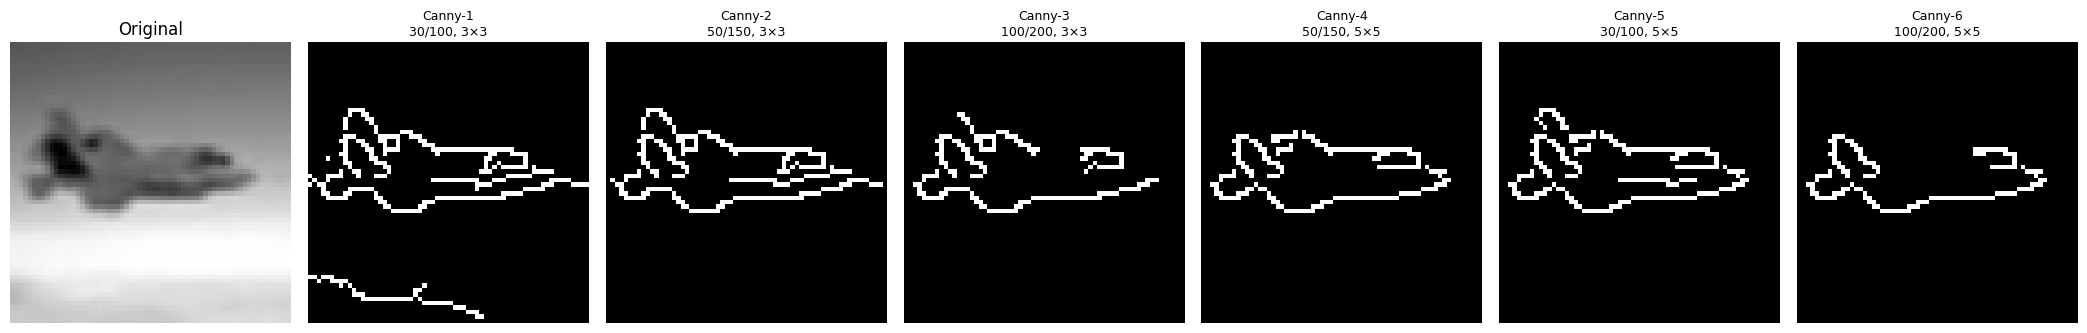

In [ ]:
fig, ax = plt.subplots(1, len(CANNY_CFGS) + 1, figsize=(3 * (len(CANNY_CFGS) + 1), 3.2))
ax[0].imshow(imgs[rep[0]], cmap="gray"); ax[0].set_title("Original"); ax[0].axis("off")
for a, (n, lo, hi, k) in zip(ax[1:], CANNY_CFGS):
    a.imshow(canny(imgs[rep[0]], lo, hi, k), cmap="gray"); a.set_title(f"{n}\n{lo}/{hi}, {k}×{k}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig("results/task3_canny_params.png", dpi=150); plt.show()

## Choosing the edge representation for Set C
Every edge detector is scored with the same quick validation test (macro-F1 on 16×16 edge maps); the best one becomes **Set C**. The raw / filtered scores are shown as references.

In [ ]:
_, lo, hi, k = BEST_CANNY
CANDS = {"Sobel (magnitude)": DETECTORS["Sobel"], "Prewitt": DETECTORS["Prewitt"], "Laplacian": DETECTORS["Laplacian"],
         "LoG": DETECTORS["LoG"], f"Canny ({lo}/{hi}, {k}×{k})": lambda im: canny(im, lo, hi, k)}
sc = {n: 100 * quick_score(f) for n, f in CANDS.items()}
sc_ref = {"[ref] Raw images": 100 * quick_score(lambda im: im),
          f"[ref] Filtered ({CFG['best_filter']})": 100 * quick_score(FILTERS[CFG["best_filter"]])}
edge_cmp = pd.Series({**sc, **sc_ref}, name="val macro-F1 (%)").round(2).to_frame()
BEST_EDGE = max(sc, key=sc.get); EDGE_FN = CANDS[BEST_EDGE]
edge_cmp.to_csv("results/edge_method_comparison.csv"); print("Best edge representation:", BEST_EDGE); edge_cmp

Best edge representation: Canny (50/150, 3×3)


,val macro-F1 (%)
Sobel (magnitude),42.44
Prewitt,42.69
Laplacian,42.76
LoG,43.15
"Canny (50/150, 3×3)",43.65
[ref] Raw images,43.00
[ref] Filtered (gaussian),44.55


## Task 4 — Build Set A (raw), Set B (filtered), Set C (edge)

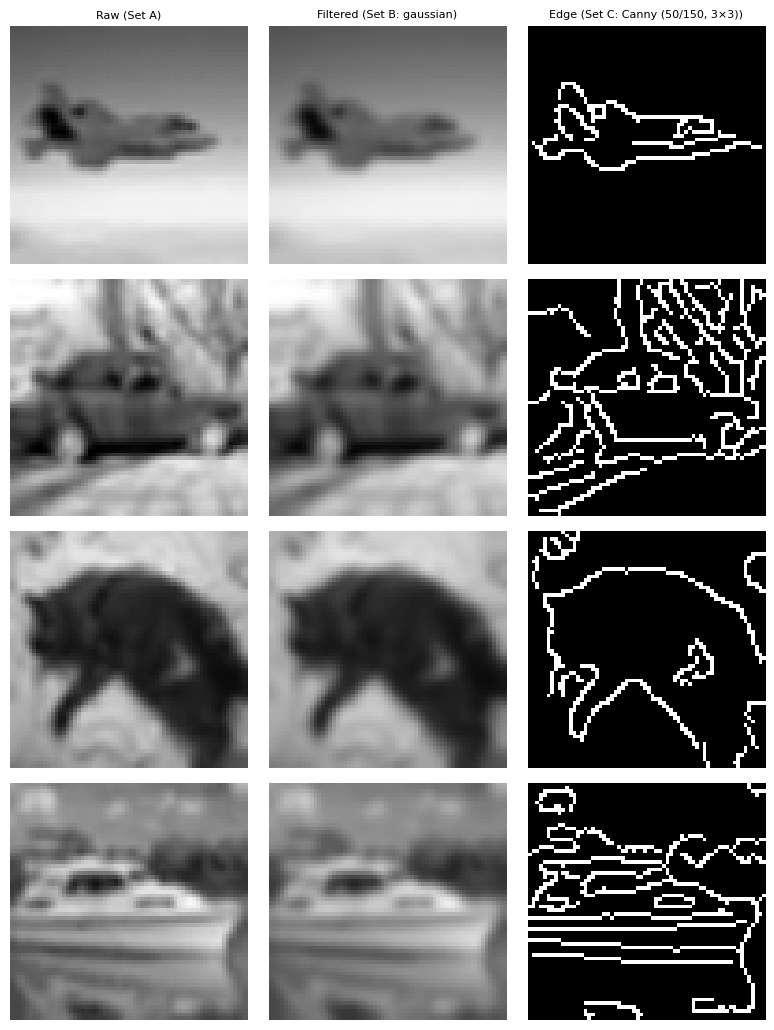

In [ ]:
FILT = FILTERS[CFG["best_filter"]]
SETS = {"Raw (Set A)": imgs,
        f"Filtered (Set B: {CFG['best_filter']})": np.array([FILT(im) for im in imgs]),
        f"Edge (Set C: {BEST_EDGE})": np.array([to_u8(EDGE_FN(im)) for im in imgs])}
SET_KEYS = list(SETS)
fig, ax = plt.subplots(n_classes, 3, figsize=(8, 2.6 * n_classes))
for r, i in enumerate(rep):
    for c, kname in enumerate(SET_KEYS):
        ax[r, c].imshow(SETS[kname][i], cmap="gray", vmin=0, vmax=255); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(kname, fontsize=8)
plt.tight_layout(); plt.savefig("results/task4_datasets.png", dpi=150); plt.show()

## Task 5 — Train & evaluate (identical split, epochs, metrics for all sets)
Classical models use 32×32 pixel vectors (standardised for SVM/KNN); `C` (SVM) and `k` (KNN) are chosen on the **validation** set. CNNs use the 64×64 image, the same `epochs/lr/batch`, and keep the best-validation epoch. Precision/recall/F1 are **macro-averaged** on the **test** set; inference time is ms per image.

In [ ]:
def classical_feats(arr): return np.stack([cv2.resize(a, (32, 32), interpolation=cv2.INTER_AREA).ravel() / 255. for a in arr]).astype(np.float32)

def metrics(yt, yp):
    return dict(acc=100 * accuracy_score(yt, yp), prec=100 * precision_score(yt, yp, average="macro", zero_division=0),
                rec=100 * recall_score(yt, yp, average="macro", zero_division=0), f1=100 * f1_score(yt, yp, average="macro", zero_division=0))

GRID = {"SVM": [dict(C=1), dict(C=10)], "KNN": [dict(k=3), dict(k=5), dict(k=7)], "Random Forest": [dict(n=200)]}
def build(name, p):
    if name == "SVM": return make_pipeline(StandardScaler(), SVC(C=p["C"], kernel="rbf", random_state=SEED))
    if name == "KNN": return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=p["k"]))
    return RandomForestClassifier(n_estimators=p["n"], random_state=SEED, n_jobs=-1)

def run_classical(name, arr):
    X = classical_feats(arr); best = None
    for p in GRID[name]:
        m = build(name, p); t0 = time.time(); m.fit(X[tr], y[tr]); tt = time.time() - t0
        va_acc = accuracy_score(y[va], m.predict(X[va]))
        if best is None or va_acc > best[0]: best = (va_acc, m, tt, p)
    va_acc, m, tt, p = best
    t0 = time.time(); pred = m.predict(X[te]); inf = (time.time() - t0) / len(te) * 1000
    return dict(val_acc=100 * va_acc, train_s=tt, infer_ms=inf, pred=pred, model=m, params=p)

class CNN1(nn.Module):
    def __init__(s, nc):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.AdaptiveAvgPool2d(8))
        s.c = nn.Sequential(nn.Flatten(), nn.Linear(32 * 64, 64), nn.ReLU(), nn.Linear(64, nc))
    def forward(s, x): return s.c(s.f(x))
class CNN2(nn.Module):
    def __init__(s, nc):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        s.f = nn.Sequential(blk(1, 32), blk(32, 64), blk(64, 128), nn.AdaptiveAvgPool2d(1))
        s.c = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, nc))
    def forward(s, x): return s.c(s.f(x))

def predict_t(model, X):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), 256): out.append(model(X[i:i + 256].to(DEVICE)).argmax(1).cpu())
    return torch.cat(out).numpy()

def run_cnn(Net, arr):
    torch.manual_seed(SEED)
    X = torch.tensor(arr, dtype=torch.float32).div(255).unsqueeze(1); Y = torch.tensor(y)
    model = Net(n_classes).to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"]); lossf = nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(SEED); best = (-1, None); t0 = time.time()
    for ep in range(CFG["epochs"]):
        model.train(); perm = tr[torch.randperm(len(tr), generator=g).numpy()]
        for i in range(0, len(perm), CFG["batch"]):
            b = perm[i:i + CFG["batch"]]; opt.zero_grad()
            lossf(model(X[b].to(DEVICE)), Y[b].to(DEVICE)).backward(); opt.step()
        va_acc = accuracy_score(y[va], predict_t(model, X[va]))
        if va_acc > best[0]: best = (va_acc, {k: v.clone() for k, v in model.state_dict().items()})
    tt = time.time() - t0; model.load_state_dict(best[1])
    t1 = time.time(); pred = predict_t(model, X[te]); inf = (time.time() - t1) / len(te) * 1000
    return dict(val_acc=100 * best[0], train_s=tt, infer_ms=inf, pred=pred, model=model, params={})

results = []
for kname in SET_KEYS:
    arr = SETS[kname]
    for name in ["SVM", "Random Forest", "KNN"]:
        r = run_classical(name, arr); r.update(Model=name, Set=kname); results.append(r)
        print(f"{name:14s} | {kname:38s} | val {r['val_acc']:.1f}  test {accuracy_score(y[te], r['pred'])*100:.1f}  train {r['train_s']:.1f}s")
    for name, Net in [("CNN Model 1", CNN1), ("CNN Model 2", CNN2)]:
        r = run_cnn(Net, arr); r.update(Model=name, Set=kname); results.append(r)
        print(f"{name:14s} | {kname:38s} | val {r['val_acc']:.1f}  test {accuracy_score(y[te], r['pred'])*100:.1f}  train {r['train_s']:.1f}s")
for r in results: r.update(metrics(y[te], r["pred"]))

SVM            | Raw (Set A)                            | val 57.8  test 56.5  train 0.7s
Random Forest  | Raw (Set A)                            | val 62.0  test 57.2  train 6.1s
KNN            | Raw (Set A)                            | val 41.5  test 39.0  train 0.0s
CNN Model 1    | Raw (Set A)                            | val 61.8  test 58.8  train 63.0s
CNN Model 2    | Raw (Set A)                            | val 68.2  test 69.0  train 246.1s
SVM            | Filtered (Set B: gaussian)             | val 57.2  test 56.5  train 0.7s
Random Forest  | Filtered (Set B: gaussian)             | val 61.5  test 57.2  train 6.0s
KNN            | Filtered (Set B: gaussian)             | val 42.0  test 45.0  train 0.0s
CNN Model 1    | Filtered (Set B: gaussian)             | val 60.5  test 57.0  train 53.0s
CNN Model 2    | Filtered (Set B: gaussian)             | val 67.8  test 65.2  train 236.9s
SVM            | Edge (Set C: Canny (50/150, 3×3))      | val 50.0  test 53.5  train 0.9s
Rand

In [ ]:
full = pd.DataFrame([{k: r[k] for k in ["Model", "Set", "val_acc", "acc", "prec", "rec", "f1", "train_s", "infer_ms"]} for r in results]).round(3)
full.columns = ["Model", "Dataset", "Val acc (%)", "Test acc (%)", "Precision (%)", "Recall (%)", "F1 (%)", "Train time (s)", "Inference (ms/img)"]
full.to_csv("results/table3b_full_results.csv", index=False)

order = ["SVM", "Random Forest", "KNN", "CNN Model 1", "CNN Model 2"]
t3 = []
for m in order:
    row = {"Model / Classifier": m}
    for lab, kname in zip(["Accuracy Raw (Lab 1)", "Accuracy Filtered (Lab 2)", "Accuracy Edge (Lab 3)"], SET_KEYS):
        row[lab] = round(full[(full.Model == m) & (full.Dataset == kname)]["Test acc (%)"].iloc[0], 2)
    e = full[(full.Model == m) & (full.Dataset == SET_KEYS[2])].iloc[0]       # P / R / F1 / times refer to the EDGE set
    row.update({"Precision (Edge, %)": e["Precision (%)"], "Recall (Edge, %)": e["Recall (%)"], "F1-Score (Edge, %)": e["F1 (%)"],
                "Training Time (s)": e["Train time (s)"], "Inference Time (ms)": e["Inference (ms/img)"]})
    t3.append(row)
table3 = pd.DataFrame(t3); table3.to_csv("results/table3_cross_lab.csv", index=False)
print("Table 3 (accuracy for all three sets; precision/recall/F1/time reported for the Edge set). Full detail = table3b below.")
display(table3); full

Table 3 (accuracy for all three sets; precision/recall/F1/time reported for the Edge set). Full detail = table3b below.


,Model / Classifier,Accuracy Raw (Lab 1),Accuracy Filtered (Lab 2),Accuracy Edge (Lab 3),"Precision (Edge, %)","Recall (Edge, %)","F1-Score (Edge, %)",Training Time (s),Inference Time (ms)
0,SVM,56.50,56.50,53.50,52.654,53.50,52.706,0.928,2.080
1,Random Forest,57.25,57.25,53.25,52.749,53.25,52.581,2.326,0.163
2,KNN,39.00,45.00,27.50,46.872,27.50,19.843,0.018,0.117
3,CNN Model 1,58.75,57.00,66.00,66.464,66.00,65.724,52.715,1.339
4,CNN Model 2,69.00,65.25,64.50,67.663,64.50,64.602,246.255,5.165


,Model,Dataset,Val acc (%),Test acc (%),Precision (%),Recall (%),F1 (%),Train time (s),Inference (ms/img)
0,SVM,Raw (Set A),57.75,56.50,56.651,56.50,56.317,0.741,0.905
1,Random Forest,Raw (Set A),62.00,57.25,57.235,57.25,57.218,6.125,0.168
2,KNN,Raw (Set A),41.50,39.00,50.191,39.00,38.050,0.019,0.139
3,CNN Model 1,Raw (Set A),61.75,58.75,59.697,58.75,58.619,63.037,1.484
4,CNN Model 2,Raw (Set A),68.25,69.00,71.816,69.00,69.011,246.086,6.441
5,SVM,Filtered (Set B: gaussian),57.25,56.50,56.676,56.50,56.332,0.675,1.036
6,Random Forest,Filtered (Set B: gaussian),61.50,57.25,57.206,57.25,57.172,6.030,0.169
7,KNN,Filtered (Set B: gaussian),42.00,45.00,53.855,45.00,43.939,0.026,0.193
8,CNN Model 1,Filtered (Set B: gaussian),60.50,57.00,57.746,57.00,56.945,53.047,1.756
9,CNN Model 2,Filtered (Set B: gaussian),67.75,65.25,66.830,65.25,65.279,236.933,5.038


## Task 6 — Visual comparison for the best-performing model
*Best* = highest mean **validation** accuracy over the three sets (the test set is not used to pick it).

Best model: CNN Model 2 
 Model
CNN Model 2      65.08
CNN Model 1      62.08
Random Forest    57.83
SVM              55.00
KNN              37.00


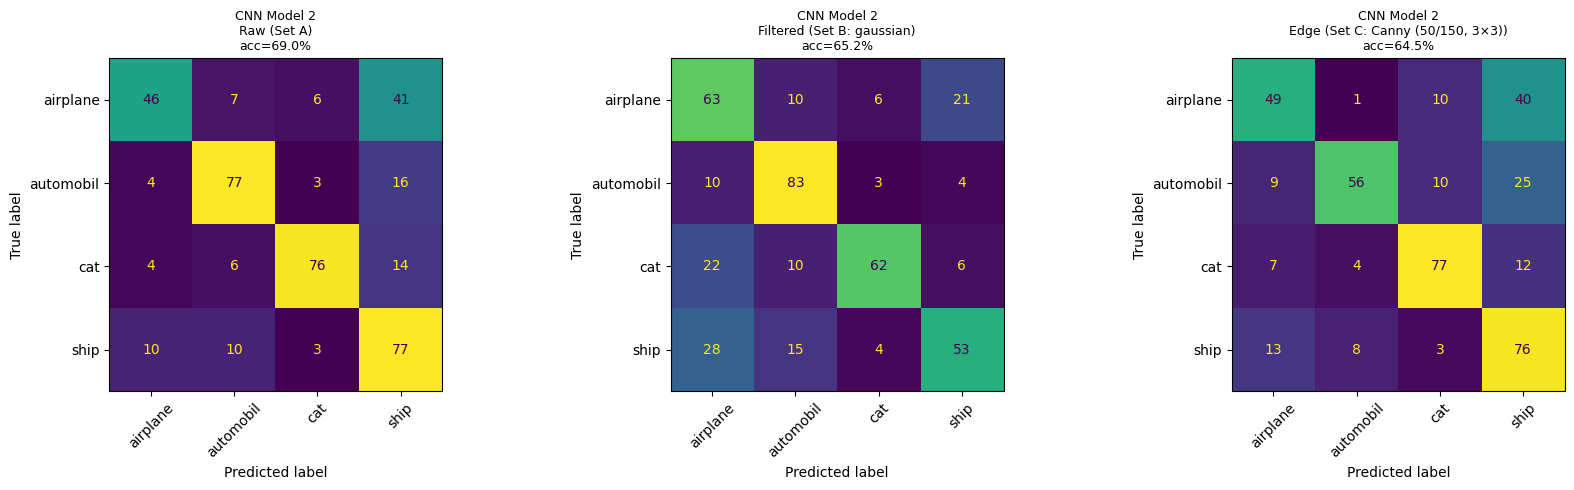

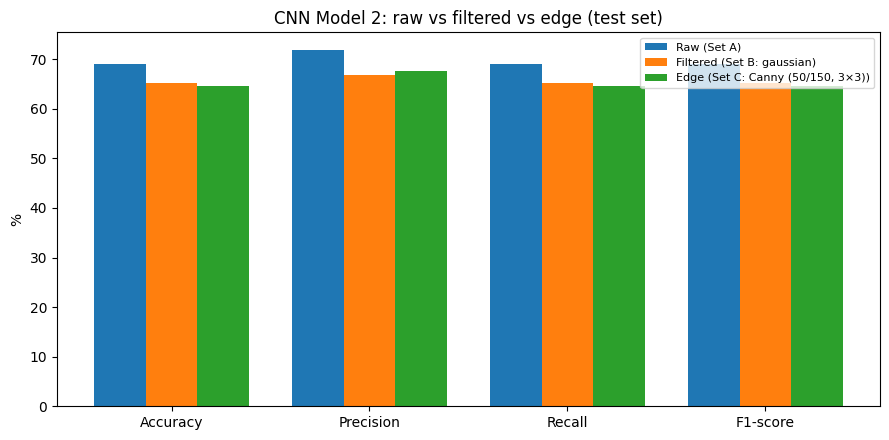

In [ ]:
mean_val = full.groupby("Model")["Val acc (%)"].mean().sort_values(ascending=False)
BEST_MODEL = mean_val.index[0]; print("Best model:", BEST_MODEL, "\n", mean_val.round(2).to_string())
sel = {r["Set"]: r for r in results if r["Model"] == BEST_MODEL}

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, kname in zip(ax, SET_KEYS):
    ConfusionMatrixDisplay(confusion_matrix(y[te], sel[kname]["pred"]), display_labels=[c[:9] for c in class_names]).plot(ax=a, colorbar=False, xticks_rotation=45)
    a.set_title(f"{BEST_MODEL}\n{kname}\nacc={sel[kname]['acc']:.1f}%", fontsize=9)
plt.tight_layout(); plt.savefig("results/task6_confusion_matrices.png", dpi=150); plt.show()

keys = [("acc", "Accuracy"), ("prec", "Precision"), ("rec", "Recall"), ("f1", "F1-score")]
x = np.arange(len(keys)); w = 0.26
plt.figure(figsize=(9, 4.5))
for j, kname in enumerate(SET_KEYS): plt.bar(x + (j - 1) * w, [sel[kname][k] for k, _ in keys], w, label=kname)
plt.xticks(x, [n for _, n in keys]); plt.ylabel("%"); plt.title(f"{BEST_MODEL}: raw vs filtered vs edge (test set)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/task6_metric_bars.png", dpi=150); plt.show()

### Relating traditional edge filters to learned CNN features
First-layer 3×3 kernels of CNN Model 1 (trained on raw images) next to the hand-crafted Sobel / Prewitt kernels.

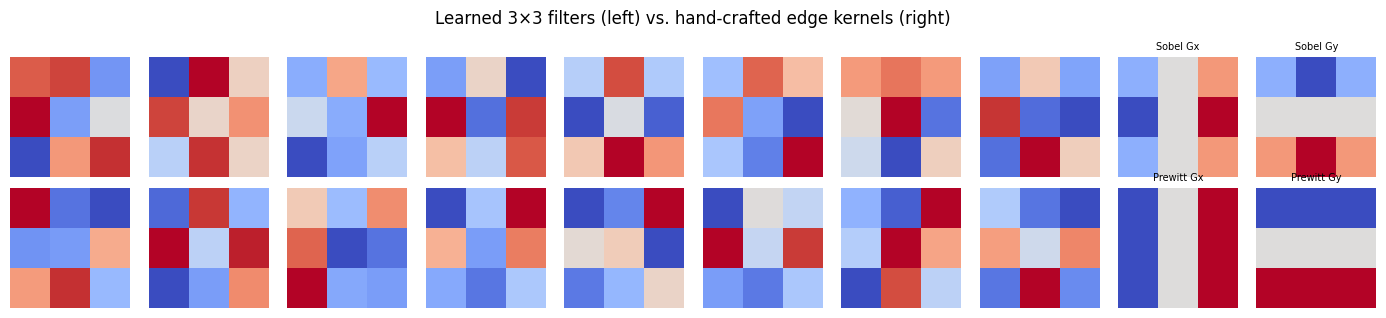

In [ ]:
m1 = next(r["model"] for r in results if r["Model"] == "CNN Model 1" and r["Set"] == SET_KEYS[0])
W = m1.f[0].weight.detach().cpu().numpy()[:, 0]
fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for k in range(16): ax[k // 8, k % 8].imshow(W[k], cmap="coolwarm"); ax[k // 8, k % 8].axis("off")
for j, (kern, t) in enumerate([(np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]), "Sobel Gx"), (np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]), "Sobel Gy"),
                               (KP_X, "Prewitt Gx"), (KP_Y, "Prewitt Gy")]):
    a = ax[j // 2, 8 + j % 2]; a.imshow(kern, cmap="coolwarm"); a.set_title(t, fontsize=7); a.axis("off")
plt.suptitle("Learned 3×3 filters (left) vs. hand-crafted edge kernels (right)"); plt.tight_layout()
plt.savefig("results/cnn_vs_edge_kernels.png", dpi=150); plt.show()

## Auto-generated summary

In [ ]:
rawk, filk, edgk = SET_KEYS
best_rows = {k: sel[k] for k in SET_KEYS}
d_edge = best_rows[edgk]["acc"] - best_rows[rawk]["acc"]; d_filt = best_rows[filk]["acc"] - best_rows[rawk]["acc"]
per_set = full.groupby("Dataset")["Test acc (%)"].mean().round(2)
print(f"Classes: {class_names} | train/val/test = {len(tr)}/{len(va)}/{len(te)}")
print(f"Best edge representation: {BEST_EDGE}; best Canny config: {BEST_CANNY}")
print(f"Best model ({BEST_MODEL}) test accuracy: raw {best_rows[rawk]['acc']:.2f} | filtered {best_rows[filk]['acc']:.2f} | edge {best_rows[edgk]['acc']:.2f}")
print(f"Edge vs raw: {d_edge:+.2f} pts  ->  edge detection {'IMPROVED' if d_edge > 0.5 else ('REDUCED' if d_edge < -0.5 else 'did not change')} accuracy for {BEST_MODEL}")
print(f"Filtered vs raw: {d_filt:+.2f} pts")
print("Mean test accuracy over all 5 models per dataset:"); print(per_set.to_string())

Classes: ['airplane', 'automobile', 'cat', 'ship'] | train/val/test = 1200/400/400
Best edge representation: Canny (50/150, 3×3); best Canny config: ('Canny-2', 50, 150, 3)
Best model (CNN Model 2) test accuracy: raw 69.00 | filtered 65.25 | edge 64.50
Edge vs raw: -4.50 pts  ->  edge detection REDUCED accuracy for CNN Model 2
Filtered vs raw: -3.75 pts
Mean test accuracy over all 5 models per dataset:
Dataset
Edge (Set C: Canny (50/150, 3×3))    52.95
Filtered (Set B: gaussian)           56.20
Raw (Set A)                          56.10


## Discussion

**Does edge detection help classification?** Read the *Auto-generated summary* and Table 3 for the outcome on your data. In general, an edge map throws away intensity/texture information and keeps only structure. That helps when class identity is carried by shape/contours and illumination/background variation is a nuisance, and it hurts when colour/intensity statistics or fine texture are discriminative (then Raw or Filtered images usually win). Classical models fed pixel vectors are especially affected, because a thin binary edge map is sparse and not translation-tolerant; CNNs can exploit edge maps better because their pooling layers give spatial tolerance. Report whichever you observe and comment on *why*.

**Detectors.** First-order operators (Sobel/Prewitt) are cheap but thick and noise-sensitive; Laplacian (second-order) is the most noise-sensitive and double-responds; LoG smooths first, so it is more robust but blurs/rounds corners; Canny (smoothing + non-maximum suppression + hysteresis) gives thin, mostly continuous edges and is the most robust, but needs thresholds tuned to the data.

**Noise and smoothing (Table 1).** Gaussian filtering suppresses Gaussian noise well but also softens true edges; median filtering is the right choice for salt-and-pepper (impulse) noise because it removes isolated outliers while preserving edges. Using Gaussian filtering on salt-and-pepper noise smears impulses rather than removing them.

**Canny parameters (Table 2).** Low thresholds / small kernels → dense edges with many false/texture edges; high thresholds / larger kernels → clean but sparse edges with broken contours. The best configuration is the one that maximises downstream discriminability on *your* dataset (selected by validation macro-F1 above).

**Edge features vs. CNN features.** Edge detectors are fixed, hand-designed filters; the first CNN layer typically *learns* oriented edge/blob detectors very similar to Sobel/Prewitt/Gabor kernels (see the filter figure) and then composes them hierarchically into textures, parts and objects. Learned filters adapt to the task, whereas Sobel/Canny are task-agnostic.

**Fairness.** Same split, epochs, optimiser, seed and metrics for all three sets; hyper-parameters and the best epoch were chosen on validation data; the test set was used only for the reported numbers.